In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Data Loading
df = pd.read_excel('sample - superstore (2).xlsx')
print(df.head(10))
print("Shape:", df.shape)
print(df.info())

   Row ID        Order ID Order Date  Ship Date       Ship Mode Customer ID  \
0    2718  CA-2016-100006 2016-09-07 2016-09-13  Standard Class    DK-13375   
1    6288  CA-2016-100090 2016-07-08 2016-07-12  Standard Class    EB-13705   
2    6289  CA-2016-100090 2016-07-08 2016-07-12  Standard Class    EB-13705   
3    9515  CA-2016-100293 2016-03-14 2016-03-18  Standard Class    NF-18475   
4    3084  CA-2016-100328 2016-01-28 2016-02-03  Standard Class    JC-15340   
5    3836  CA-2016-100363 2016-04-08 2016-04-15  Standard Class    JM-15655   
6    3837  CA-2016-100363 2016-04-08 2016-04-15  Standard Class    JM-15655   
7    9441  CA-2016-100391 2016-05-25 2016-05-29  Standard Class    BW-11065   
8    6569  CA-2016-100678 2016-04-18 2016-04-22  Standard Class    KM-16720   
9    6570  CA-2016-100678 2016-04-18 2016-04-22  Standard Class    KM-16720   

      Customer Name      Segment Country/Region           City  ...  \
0       Dennis Kane     Consumer  United States  New York C

In [4]:
# 2. Data Cleaning
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Ship Date'] = pd.to_datetime(df['Ship Date'])
df = df.drop_duplicates()
print("Cleaning Done, New Shape:", df.shape)


Row ID             0
Order ID           0
Order Date         0
Ship Date          0
Ship Mode          0
Customer ID        0
Customer Name      0
Segment            0
Country/Region     0
City               0
State              0
Postal Code       11
Region             0
Product ID         0
Category           0
Sub-Category       0
Product Name       0
Sales              0
Quantity           0
Discount           0
Profit             0
dtype: int64
Duplicates: 0
Cleaning Done, New Shape: (9994, 21)


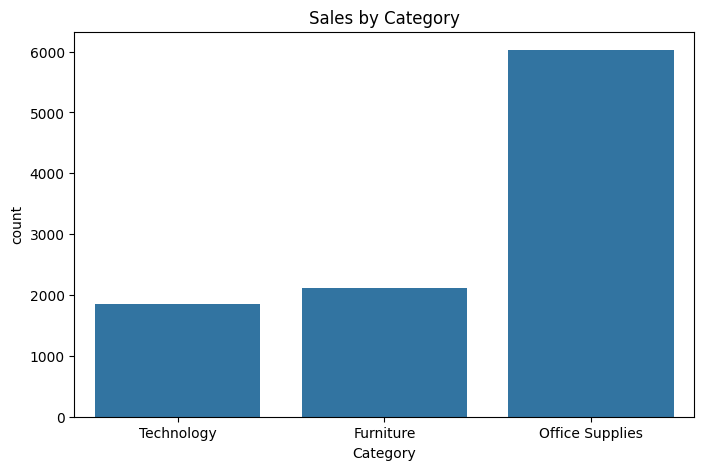

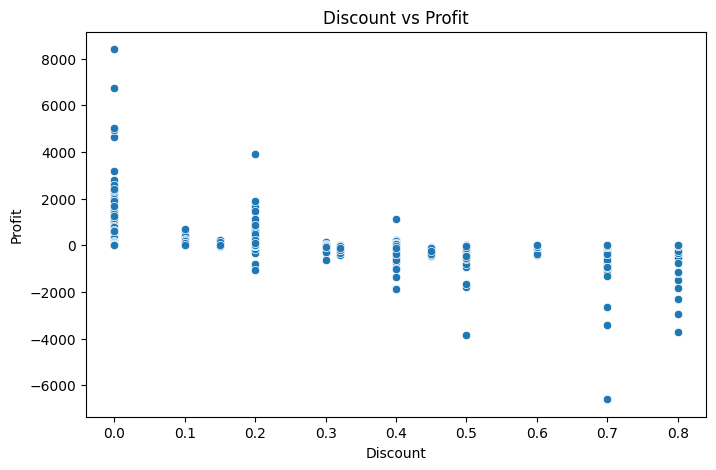

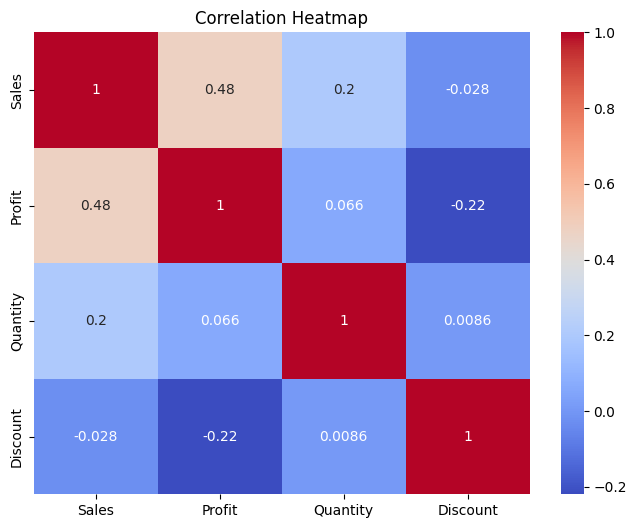

In [5]:
# 3. Graphs
plt.figure(figsize=(8,5))
sns.countplot(x='Category', data=df)
plt.title('Sales by Category')
plt.show()

plt.figure(figsize=(8,5))
sns.scatterplot(x='Discount', y='Profit', data=df)
plt.title('Discount vs Profit')
plt.show()

plt.figure(figsize=(8,6))
sns.heatmap(df[['Sales','Profit','Quantity','Discount']].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

In [6]:
# 4. Insights for Report
print(df.groupby('Category')[['Sales','Profit']].sum())
print(df.groupby('Region')[['Sales','Profit']].sum())
print(df.groupby('Sub-Category')['Profit'].sum().nsmallest(3))

                       Sales       Profit
Category                                 
Furniture        741999.7953   18451.2728
Office Supplies  719047.0320  122490.8008
Technology       836154.0330  145454.9481
                  Sales       Profit
Region                              
'NorthEast     259.4400      19.7043
Central     501239.8908   39706.3625
East        678521.8000   91503.0757
South       391721.9050   46749.4303
West        725457.8245  108418.4489
Sub-Category
Tables      -17725.4811
Bookcases    -3472.5560
Supplies     -1189.0995
Name: Profit, dtype: float64
